# Práctica 6. Puerta de Hadamard

## Información general

**Asignatura:** Computación cuántica  
**Sesión:** 6  
**Título:** Puerta de Hadamard
**Modalidad:** Individual  
**Entorno recomendado:** Jupyter Notebook  
**Bibliotecas:** NumPy, Matplotlib, Qiskit y Qiskit Aer

## Objetivos

En esta práctica vas a estudiar la puerta de Hadamard desde tres puntos de vista:

- Cálculo manual con vectores y matrices.
- Implementación con NumPy.
- Construcción y simulación de circuitos con Qiskit.

Al finalizar la práctica deberás ser capaz de:

- Escribir la matriz de Hadamard.
- Aplicar Hadamard sobre $|0\rangle$ y $|1\rangle$.
- Interpretar los estados $|+\rangle$ y $|-\rangle$.
- Comprobar que $H^2 = I$.
- Entender Hadamard como cambio entre la base $Z$ y la base $X$.
- Construir superposiciones uniformes con varios qubits.
- Analizar cómo una fase relativa puede convertirse en una diferencia de probabilidad.
- Comparar probabilidades teóricas y conteos experimentales.

## Entrega

Entrega este notebook completado con código ejecutado, resultados visibles, tablas completadas, respuestas razonadas y conclusión final.

## 1. Preparación del entorno

Ejecuta la siguiente celda para importar las bibliotecas necesarias.

In [36]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

SEMILLA = 20

## 2. Parte A. Hadamard con matrices

### Ejercicio 1. Definición de estados y matriz de Hadamard

Define con NumPy los estados:

$$
|0\rangle =
\begin{pmatrix}
1 \\
0
\end{pmatrix}
$$

$$
|1\rangle =
\begin{pmatrix}
0 \\
1
\end{pmatrix}
$$

y la matriz:

$$
H =
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
$$

Muestra $|0\rangle$, $|1\rangle$, $H$ y la forma de cada array con `.shape`.

In [37]:
# TODO: define los estados y la matriz de Hadamard
ket_0 = np.array([1,0], dtype=complex)
ket_1 = np.array([0,1], dtype=complex)

H = np.matrix([[1,1],[1,-1]] / np.sqrt(2), dtype=complex)

print("|0> =", ket_0)
print("|1> =", ket_1)
print("H =")
print(H)

print("shape |0>:", ...)
print("shape |1>:", ...)
print("shape H:", ...)

|0> = [1.+0.j 0.+0.j]
|1> = [0.+0.j 1.+0.j]
H =
[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]
shape |0>: Ellipsis
shape |1>: Ellipsis
shape H: Ellipsis


**Responde:**

1. ¿Qué dimensión tienen los estados $|0
\rangle$ y $|1
\rangle$?
2. ¿Qué dimensión tiene la matriz $H$?
3. ¿Por qué tiene sentido multiplicar $H$ por un estado de un qubit?

Respuesta:

1. Vectores de 2 componentes.
2. Matriz $2\times2$.
3. Sus dimensiones son compatibles.

### Ejercicio 2. Cálculo de $H|0\rangle$

Calcula con NumPy:

$$
H|0\rangle
$$

Después, desarrolla manualmente el producto en una celda Markdown.

In [38]:
# TODO: calcula H|0>
estado_h0 = H @ ket_0

print("H|0> =", estado_h0)

H|0> = [[0.70710678+0.j 0.70710678+0.j]]


Desarrollo manual:

$$
H|0\rangle=\frac{1}{\sqrt2}
\begin{pmatrix}1&1\\1&-1\end{pmatrix}
\begin{pmatrix}1\\0\end{pmatrix}
=\frac{1}{\sqrt2}\begin{pmatrix}1\\1\end{pmatrix}=|+\rangle.
$$

**Responde:**

1. ¿Qué estado se obtiene?
2. ¿Cuáles son sus amplitudes?
3. ¿Cuáles son sus probabilidades de medida?
4. ¿Qué nombre recibe este estado?

Respuesta:

1. $|+\rangle$.
2. $(1/\sqrt2,1/\sqrt2)$.
3. $P(0)=P(1)=1/2$.
4. Estado más.

### Ejercicio 3. Cálculo de $H|1\rangle$

Calcula con NumPy:

$$
H|1\rangle
$$

Después, desarrolla manualmente el producto en una celda Markdown.

In [39]:
# TODO: calcula H|1>
estado_h1 = H @ ket_1

print("H|1> =", estado_h1)

H|1> = [[ 0.70710678+0.j -0.70710678+0.j]]


Desarrollo manual:

$$
H|1\rangle=\frac{1}{\sqrt2}
\begin{pmatrix}1&1\\1&-1\end{pmatrix}
\begin{pmatrix}0\\1\end{pmatrix}
=\frac{1}{\sqrt2}\begin{pmatrix}1\\-1\end{pmatrix}=|-\rangle.
$$

**Responde:**

1. ¿Qué estado se obtiene?
2. ¿Cuáles son sus amplitudes?
3. ¿Cuáles son sus probabilidades de medida?
4. ¿Qué diferencia hay entre este estado y $H|0\rangle$?

Respuesta:

1. $|-\rangle$.
2. $(1/\sqrt2,-1/\sqrt2)$.
3. $P(0)=P(1)=1/2$.
4. La fase relativa del segundo término.

### Ejercicio 4. Función para calcular probabilidades

Implementa una función que devuelva las probabilidades de medir 0 y 1 en la base computacional.

In [40]:
def probabilidades(estado):
    """
    Devuelve las probabilidades de medir 0 y 1
    en la base computacional.
    """
    estado = np.asarray(estado, dtype=complex).ravel()
    probs = np.abs(estado) ** 2
    return {0: float(probs[0]), 1: float(probs[1])}

In [41]:
estados = {
    "|0>": ket_0,
    "|1>": ket_1,
    "H|0>": estado_h0,
    "H|1>": estado_h1,
}

for nombre, estado in estados.items():
    print(nombre, probabilidades(estado))

|0> {0: 1.0, 1: 0.0}
|1> {0: 0.0, 1: 1.0}
H|0> {0: 0.4999999999999999, 1: 0.4999999999999999}
H|1> {0: 0.4999999999999999, 1: 0.4999999999999999}


Completa la tabla:

| Estado | P(0) | P(1) |
|---|---:|---:|
| $\|0\rangle$ | 1 | 0 |
| $\|1\rangle$ | 0 | 1 |
| $H\|0\rangle$ | 0.5 | 0.5 |
| $H\|1\rangle$ | 0.5 | 0.5 |

## 3. Parte B. Propiedad $H^2=I$

### Ejercicio 5. Comprobación matricial

Calcula con NumPy:

$$
H^2
$$

y compara el resultado con la matriz identidad.

In [42]:
# TODO: calcula H^2 y compáralo con la identidad
H2 = H @ H
I = np.eye(2, dtype=complex)

print("H^2 =")
print(H2)

print("I =")
print(I)

print("¿H^2 = I?", np.allclose(H2, I))

H^2 =
[[ 1.00000000e+00+0.j -2.23711432e-17+0.j]
 [-2.23711432e-17+0.j  1.00000000e+00+0.j]]
I =
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]
¿H^2 = I? True


**Responde:**

1. ¿Qué matriz se obtiene al calcular $H^2$?
2. ¿Qué significa que $H^2=I$?
3. ¿Por qué puede haber pequeñas diferencias numéricas?
4. ¿Por qué usamos `np.allclose` en lugar de `==`?

Respuesta:

1. La identidad $I$.
2. Dos Hadamard restauran el estado.
3. Por el redondeo en coma flotante.
4. `np.allclose` admite pequeños errores numéricos.

### Ejercicio 6. Aplicar Hadamard dos veces a un estado

Calcula:

$$
HH|0\rangle
$$

y:

$$
HH|1\rangle
$$

In [43]:
# TODO: calcula HH|0> y HH|1>
estado_hh0 = H2 @ ket_0
estado_hh1 = H2 @ ket_1

print("HH|0> =", estado_hh0)
print("HH|1> =", estado_hh1)

HH|0> = [[ 1.00000000e+00+0.j -2.23711432e-17+0.j]]
HH|1> = [[-2.23711432e-17+0.j  1.00000000e+00+0.j]]


**Responde:**

1. ¿Qué ocurre al aplicar Hadamard dos veces sobre $|0\rangle$?
2. ¿Qué ocurre al aplicarla dos veces sobre $|1\rangle$?
3. ¿Cómo se relaciona esto con $H^2=I$?

Respuesta:

1. Vuelve a $|0\rangle$.
2. Vuelve a $|1\rangle$.
3. Porque $H^2=I$.

## 4. Parte C. Hadamard con Qiskit

### Ejercicio 7. Circuito con una puerta Hadamard

Crea un circuito de un qubit y aplica Hadamard.

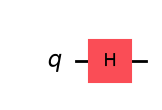

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [44]:
# TODO: crea un circuito de un qubit y aplica H
qc_h = QuantumCircuit(1)
qc_h.h(0)

estado_qiskit_h = Statevector.from_instruction(qc_h)

display(qc_h.draw("mpl"))
display(estado_qiskit_h.draw("latex"))
print(estado_qiskit_h.probabilities_dict())

**Responde:**

1. ¿Cuál es el estado inicial por defecto en Qiskit?
2. ¿Qué estado se obtiene después de aplicar $H$?
3. ¿Coincide con el cálculo de NumPy?

Respuesta:

1. $|0\rangle$.
2. $|+\rangle$.
3. Sí.

### Ejercicio 8. Circuito con dos puertas Hadamard

Crea un circuito de un qubit con dos puertas Hadamard consecutivas.

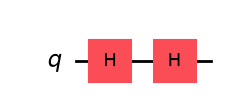

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.9999999999999996)}


In [45]:
# TODO: crea un circuito con dos H consecutivas
qc_hh = QuantumCircuit(1)
qc_hh.h(0)
qc_hh.h(0)
estado_qiskit_hh = Statevector.from_instruction(qc_hh)

display(qc_hh.draw("mpl"))
display(estado_qiskit_hh.draw("latex"))
print(estado_qiskit_hh.probabilities_dict())

**Responde:**

1. ¿Qué estado final se obtiene?
2. ¿Por qué?
3. ¿Qué propiedad de Hadamard se comprueba?

Respuesta:

1. $|0\rangle$.
2. Porque $H^2=I$.
3. Hadamard es su propia inversa.

### Ejercicio 9. Comparación $H|0\rangle$, $HH|0\rangle$, $HZH|0\rangle$

Construye tres circuitos:

- Circuito A: $H|0\rangle$
- Circuito B: $HH|0\rangle$
- Circuito C: $HZH|0\rangle$

Para cada circuito muestra el circuito, el estado final y las probabilidades.

Circuito A


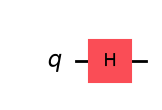

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}
Circuito B


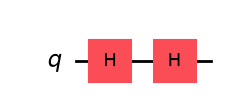

<IPython.core.display.Latex object>

{np.str_('0'): np.float64(0.9999999999999996)}
Circuito C


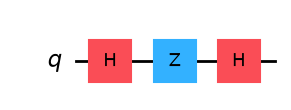

<IPython.core.display.Latex object>

{np.str_('1'): np.float64(0.9999999999999996)}


In [46]:
def analizar_circuito(qc):
    estado = Statevector.from_instruction(qc)
    display(qc.draw("mpl"))
    display(estado.draw("latex"))
    print(estado.probabilities_dict())
    return estado, estado.probabilities_dict()

# TODO: construye los tres circuitos
qc_a = QuantumCircuit(1)
qc_a.h(0)

qc_b = QuantumCircuit(1)
qc_b.h(0)
qc_b.h(0)

qc_c = QuantumCircuit(1)
qc_c.h(0)
qc_c.z(0)
qc_c.h(0)

print("Circuito A")
estado_a, probs_a = analizar_circuito(qc_a)

print("Circuito B")
estado_b, probs_b = analizar_circuito(qc_b)

print("Circuito C")
estado_c, probs_c = analizar_circuito(qc_c)

Completa la tabla:

| Circuito | Operaciones | Estado final | P(0) | P(1) |
|---|---|---|---:|---:|
| A | $H\|0\rangle$ | $\|+\rangle$ | 0.5 | 0.5 |
| B | $HH\|0\rangle$ | $\|0\rangle$ | 1 | 0 |
| C | $HZH\|0\rangle$ | $\|1\rangle$ | 0 | 1 |

**Responde:**

1. ¿Qué diferencia hay entre los circuitos B y C?
2. ¿Por qué una puerta $Z$, que solo cambia una fase, modifica el resultado final?
3. ¿Qué relación tiene este ejemplo con la interferencia?

Respuesta:

1. B obtiene 0; C obtiene 1.
2. Z cambia la fase y la segunda H convierte esa fase en probabilidad.
3. Las amplitudes interfieren constructiva o destructivamente.

## 5. Parte D. Base Z y base X

### Ejercicio 10. Construcción de $|+\rangle$ y $|-\rangle$

Define con NumPy:

$$
|+\rangle =
\frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$

$$
|-\rangle =
\frac{|0\rangle - |1\rangle}{\sqrt{2}}
$$

Comprueba que $H|0\rangle = |+\rangle$ y que $H|1\rangle = |-\rangle$.

In [47]:
# TODO: define |+> y |->
ket_plus = (ket_0+ket_1)/ np.sqrt(2)
ket_minus = (ket_0-ket_1) / np.sqrt(2)

print("|+> =", ket_plus)
print("|-> =", ket_minus)

print("H|0> = |+>?", ...)
print("H|1> = |->?", ...)

|+> = [0.70710678+0.j 0.70710678+0.j]
|-> = [ 0.70710678+0.j -0.70710678+0.j]
H|0> = |+>? Ellipsis
H|1> = |->? Ellipsis


**Responde:**

1. ¿Por qué $|+\rangle$ y $|-\rangle$ forman otra base?
2. ¿Qué nombre recibe esta base?
3. ¿Qué diferencia hay entre medir en la base Z y medir en la base X?

Respuesta:
1. Son ortogonales y normalizados.
2. Base X (Hadamard).
3. Z distingue $|0\rangle,|1\rangle$; X distingue $|+\rangle,|-\rangle$.

### Ejercicio 11. Hadamard como cambio de base

Comprueba con NumPy:

$$
H|+\rangle = |0\rangle
$$

$$
H|-\rangle = |1\rangle
$$

In [48]:
# TODO: aplica H a |+> y |- >
estado_h_plus = H @ ket_plus
estado_h_minus = H @ ket_minus

print("H|+> =", estado_h_plus)
print("H|-> =", estado_h_minus)


print("H|+> = |0>?", np.allclose(estado_h_plus, ket_0))
print("H|-> = |1>?", np.allclose(estado_h_minus, ket_1))

H|+> = [[1.+0.j 0.+0.j]]
H|-> = [[0.+0.j 1.+0.j]]
H|+> = |0>? True
H|-> = |1>? True


**Responde:**

1. ¿Qué ocurre al aplicar Hadamard a $|+\rangle$?
2. ¿Qué ocurre al aplicar Hadamard a $|-\rangle$?
3. ¿Por qué decimos que Hadamard cambia entre la base Z y la base X?

Respuesta:
1. Se convierte en $|0\rangle$.
2. Se convierte en $|1\rangle$.
3. Intercambia las bases Z y X.

## 6. Parte E. Hadamard y medida

### Ejercicio 12. Medida del estado $|+\rangle$

Construye un circuito que prepare $|+\rangle$ y lo mida con `shots = 1000`.

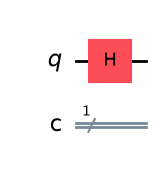

{'1': 512, '0': 488}

In [49]:
shots = 1000

# TODO: crea un circuito de un qubit y un bit clásico, prepara |+> y mide
qc_medida_plus = QuantumCircuit(1,1)
qc_medida_plus.h(0)

estado_media_plus = Statevector.from_instruction(qc_medida_plus)
display(qc_medida_plus.draw("mpl"))
qc_medida_plus.measure(0,0)

simulador = AerSimulator(seed_simulator=SEMILLA)
qc_t = transpile(qc_medida_plus, simulador)
resultado = simulador.run(qc_t, shots=shots).result()
conteos_plus = resultado.get_counts()

conteos_plus

**Responde:**

1. ¿Qué resultados se esperan aproximadamente?
2. ¿Deben aparecer exactamente 500 ceros y 500 unos?
3. ¿Qué representa el número de shots?
4. ¿La medida devuelve el estado completo?

Respuesta:
1. Unos 500 ceros y 500 unos.
2. No, hay fluctuaciones.
3. Número de ejecuciones.
4. No, solo un resultado por ejecución.

### Ejercicio 13. Efecto del número de shots

Repite la medida del estado $|+\rangle$ para distintos números de shots.

In [50]:
shots_lista = [10, 100, 1_000, 10_000]
resultados_shots = []

for n in shots_lista:
    simulador = AerSimulator(seed_simulator=SEMILLA)
    qc_t = transpile(qc_medida_plus, simulador)
    resultado = simulador.run(qc_t, shots=n).result()
    conteos = resultado.get_counts()

    n0 = conteos.get("0", 0)
    n1 = conteos.get("1", 0)

    resultados_shots.append({
        "shots": n,
        "N(0)": n0,
        "N(1)": n1,
        "f(0)": n0 / n,
        "f(1)": n1 / n,
    })

resultados_shots

[{'shots': 10, 'N(0)': 5, 'N(1)': 5, 'f(0)': 0.5, 'f(1)': 0.5},
 {'shots': 100, 'N(0)': 45, 'N(1)': 55, 'f(0)': 0.45, 'f(1)': 0.55},
 {'shots': 1000, 'N(0)': 488, 'N(1)': 512, 'f(0)': 0.488, 'f(1)': 0.512},
 {'shots': 10000, 'N(0)': 5006, 'N(1)': 4994, 'f(0)': 0.5006, 'f(1)': 0.4994}]

Completa la tabla:

| Shots | N(0) | N(1) | f(0) | f(1) |
|---:|---:|---:|---:|---:|
| 10 | 5 | 5 | 0,5 | 0,5 |
| 100 | 45 | 55 | 0,45 | 0,55 |
| 1.000 | 488 | 512 | 0,488 | 0,512 |
| 10.000 | 5006 | 4994 | 0,5006 | 0,4994 |

**Responde:**

1. ¿Qué ocurre con las frecuencias al aumentar el número de shots?
2. ¿Coinciden siempre exactamente con las probabilidades teóricas?
3. ¿Qué relación hay con la ley de los grandes números?

Respuesta:

1. Se aproximan a 0,5.
2. No siempre.
3. Las frecuencias convergen a las probabilidades.

### Ejercicio 14. Histograma de resultados

Representa en un diagrama de barras los conteos obtenidos para `shots=1000`.

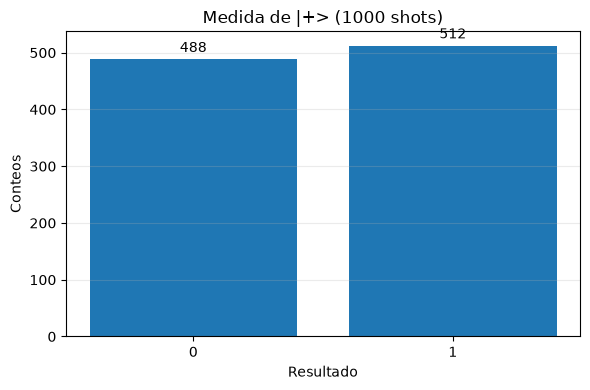

In [51]:
etiquetas = ["0", "1"]
valores = [conteos_plus.get(k, 0) for k in etiquetas]
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(etiquetas, valores)
ax.set_title("Medida de |+> (1000 shots)")
ax.set_xlabel("Resultado")
ax.set_ylabel("Conteos")
ax.grid(axis="y", alpha=0.25)
ax.bar_label(barras, padding=3)
plt.tight_layout()
plt.show()

**Responde:**

1. ¿Qué muestra el histograma?
2. ¿Muestra la fase relativa?
3. ¿Por qué un histograma no describe completamente el estado cuántico?

Respuesta:

1. Las frecuencias de 0 y 1.
2. No.
3. No muestra amplitudes ni fases.

## 7. Parte F. Hadamard en varios qubits

### Ejercicio 15. Hadamard en dos qubits

Crea un circuito de dos qubits y aplica Hadamard a ambos.

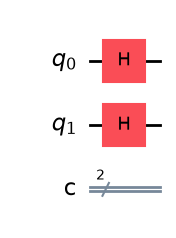

<IPython.core.display.Latex object>

{np.str_('00'): np.float64(0.2499999999999999), np.str_('01'): np.float64(0.2499999999999999), np.str_('10'): np.float64(0.2499999999999999), np.str_('11'): np.float64(0.2499999999999999)}


In [52]:
# TODO: circuito de 2 qubits con H en ambos
qc_2 = QuantumCircuit(2,2)
qc_2.h(0)
qc_2.h(1)

estado_2 = Statevector.from_instruction(qc_2)

display(qc_2.draw("mpl"))
display(estado_2.draw("latex"))
print(estado_2.probabilities_dict())

**Responde:**

1. ¿Cuántos estados aparecen en la superposición?
2. ¿Cuáles son?
3. ¿Qué probabilidad tiene cada uno?
4. ¿Por qué las probabilidades son iguales?

Respuesta:

1. Cuatro.
2. $|00\rangle,|01\rangle,|10\rangle,|11\rangle$.
3. $1/4$ cada uno.
4. Cada amplitud tiene módulo $1/2$.

### Ejercicio 16. Hadamard en tres qubits

Crea un circuito de tres qubits y aplica Hadamard a todos ellos.

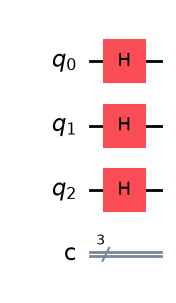

<IPython.core.display.Latex object>

{np.str_('000'): np.float64(0.12499999999999994), np.str_('001'): np.float64(0.12499999999999994), np.str_('010'): np.float64(0.12499999999999994), np.str_('011'): np.float64(0.12499999999999994), np.str_('100'): np.float64(0.12499999999999994), np.str_('101'): np.float64(0.12499999999999994), np.str_('110'): np.float64(0.12499999999999994), np.str_('111'): np.float64(0.12499999999999994)}
Estados con probabilidad no nula: 8


In [53]:
# TODO: circuito de 3 qubits con H en todos
qc_3 = QuantumCircuit(3,3)
qc_3.h(0)
qc_3.h(1)
qc_3.h(2)

estado_3 = Statevector.from_instruction(qc_3)
probs_3 = estado_3.probabilities_dict()

display(qc_3.draw("mpl"))
display(estado_3.draw("latex"))
print(probs_3)
print("Estados con probabilidad no nula:", len(probs_3))

**Responde:**

1. ¿Cuántos estados aparecen?
2. ¿Qué probabilidad tiene cada uno?
3. ¿Cómo se relaciona este resultado con $2^n$?
4. ¿Qué ocurriría con 4 qubits?

Respuesta:

1. Ocho.
2. $1/8$.
3. Hay $2^n$ estados.
4. Dieciséis estados, probabilidad $1/16$.

### Ejercicio 17. Medida de una superposición uniforme de tres qubits

Crea un circuito de tres qubits y tres bits clásicos. Aplica Hadamard a los tres qubits, mide todos y ejecuta con `shots = 1000`.

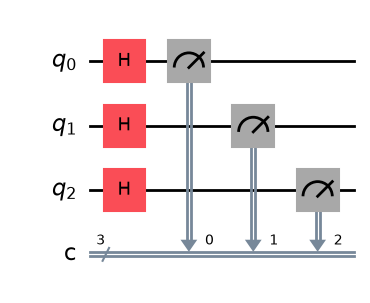

{'101': 121,
 '001': 123,
 '000': 115,
 '111': 121,
 '110': 130,
 '100': 117,
 '010': 136,
 '011': 137}

In [54]:
shots = 1000
qc_3_medida = QuantumCircuit(3, 3)
for q in range(3):
    qc_3_medida.h(q)
qc_3_medida.measure(range(3), range(3))
display(qc_3_medida.draw("mpl"))

simulador = AerSimulator(seed_simulator=SEMILLA)
qc_t = transpile(qc_3_medida, simulador)
resultado = simulador.run(qc_t, shots=shots).result()
conteos_3 = resultado.get_counts()
conteos_3

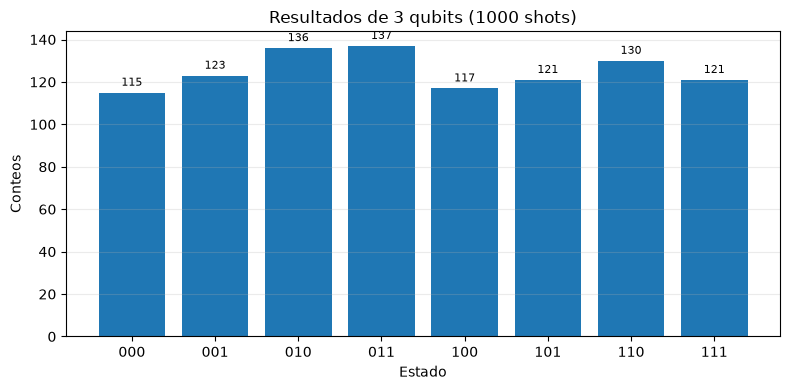

In [55]:
etiquetas = [format(i, "03b") for i in range(8)]
valores = [conteos_3.get(k, 0) for k in etiquetas]
fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(etiquetas, valores)
ax.set_title("Resultados de 3 qubits (1000 shots)")
ax.set_xlabel("Estado")
ax.set_ylabel("Conteos")
ax.grid(axis="y", alpha=0.25)
ax.bar_label(barras, padding=3, fontsize=8)
plt.tight_layout()
plt.show()

**Responde:**

1. ¿Aparecen todos los estados posibles?
2. ¿Aparecen todos con exactamente el mismo número de conteos?
3. ¿Qué se espera teóricamente?
4. ¿Por qué hay diferencias entre los conteos observados?

Respuesta:

1. Sí, normalmente aparecen los ocho.
2. No.
3. $P=1/8$ para cada estado.
4. Por la aleatoriedad de la medida.

## 8. Parte G. Superposición frente a mezcla clásica

### Ejercicio 18. Comparación conceptual

Considera dos situaciones:

Situación A:

- Se prepara el estado $|+\rangle$.
- Se mide en la base computacional.

Situación B:

- El 50 % de las veces se prepara $|0\rangle$.
- El 50 % de las veces se prepara $|1\rangle$.
- Se mide en la base computacional.

**Responde:**

1. ¿Producen ambas situaciones las mismas probabilidades al medir en la base computacional?
2. ¿Son físicamente equivalentes?
3. ¿Qué información conserva la superposición que no conserva la mezcla clásica?
4. ¿Qué operación permitiría distinguirlas?

Respuesta:

1. Sí, $50\%$ cada uno.
2. No.
3. La fase relativa (coherencia).
4. Aplicar H antes de medir.

### Ejercicio 19. Verificación con Hadamard

Explica qué ocurre si antes de medir aplicamos una puerta Hadamard a:

- El estado $|+\rangle$.
- Una mezcla clásica formada por $|0\rangle$ y $|1\rangle$ al 50 %.

**Responde:**

1. ¿Qué ocurre con $|+\rangle$ al aplicar $H$?
2. ¿Qué resultados se obtendrían en la mezcla clásica?
3. ¿Por qué esto demuestra que superposición no equivale a desconocimiento clásico?

Respuesta:

1. $H|+\rangle=|0\rangle$.
2. 50 % ceros y 50 % unos.
3. Solo la superposición conserva interferencia.

## 9. Reto avanzado

### Ejercicio 20. Generalización a $n$ qubits

Implementa una función que cree un circuito de `n` qubits con Hadamard aplicada a todos los qubits.

In [56]:
def circuito_hadamard_n_qubits(n):
    """
    Crea un circuito de n qubits con Hadamard aplicada
    a todos los qubits.
    """
    # TODO: valida que n sea positivo
    if n < 0:
        raise ValueError("Tiene que ser la 'n' positiva.")

    # TODO: crea el circuito y aplica H a todos los qubits
    qc = QuantumCircuit(n)
    for i in range(n):
        qc.h(i)

    return qc

In [57]:
for n in [1, 2, 3, 4]:
    qc = circuito_hadamard_n_qubits(n)
    estado = Statevector.from_instruction(qc)
    print("n =", n)
    print(estado.probabilities_dict())
    print()

n = 1
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}

n = 2
{np.str_('00'): np.float64(0.2499999999999999), np.str_('01'): np.float64(0.2499999999999999), np.str_('10'): np.float64(0.2499999999999999), np.str_('11'): np.float64(0.2499999999999999)}

n = 3
{np.str_('000'): np.float64(0.12499999999999994), np.str_('001'): np.float64(0.12499999999999994), np.str_('010'): np.float64(0.12499999999999994), np.str_('011'): np.float64(0.12499999999999994), np.str_('100'): np.float64(0.12499999999999994), np.str_('101'): np.float64(0.12499999999999994), np.str_('110'): np.float64(0.12499999999999994), np.str_('111'): np.float64(0.12499999999999994)}

n = 4
{np.str_('0000'): np.float64(0.06249999999999996), np.str_('0001'): np.float64(0.06249999999999996), np.str_('0010'): np.float64(0.06249999999999996), np.str_('0011'): np.float64(0.06249999999999996), np.str_('0100'): np.float64(0.06249999999999996), np.str_('0101'): np.float64(0.06249999999999996

**Responde:**

1. ¿Cuántos estados aparecen para cada valor de `n`?
2. ¿Qué probabilidad tiene cada estado?
3. ¿Qué expresión general describe el estado creado?
4. ¿Por qué esto no significa que podamos leer todos los estados a la vez?

Respuesta:

1. $2,4,8,16$ para $n=1,2,3,4$.
2. $1/2^n$.
3. $|+\rangle^{\otimes n}=\frac1{\sqrt{2^n}}\sum_{x=0}^{2^n-1}|x\rangle$.
4. Una medida devuelve una sola cadena.

## 10. Pruebas mínimas

Incluye al final del notebook las siguientes pruebas. Deben ejecutarse sin errores cuando la práctica esté completada correctamente.

In [58]:
assert np.allclose(H @ ket_0, ket_plus)
assert np.allclose(H @ ket_1, ket_minus)

I = np.eye(2, dtype=complex)
assert np.allclose(H @ H, I)

assert np.allclose(H @ ket_plus, ket_0)
assert np.allclose(H @ ket_minus, ket_1)

probs_plus = probabilidades(ket_plus)
assert np.isclose(probs_plus[0], 0.5)
assert np.isclose(probs_plus[1], 0.5)

qc = circuito_hadamard_n_qubits(3)
estado = Statevector.from_instruction(qc)
probs = estado.probabilities_dict()
assert len(probs) == 8

for p in probs.values():
    assert np.isclose(p, 1 / 8)

## 11. Conclusión final

Redacta una conclusión de entre 150 y 250 palabras respondiendo:

1. ¿Qué papel tiene la puerta de Hadamard en la computación cuántica?
2. ¿Por qué $|+\rangle$ y $|-\rangle$ no son el mismo estado aunque tengan las mismas probabilidades en la base computacional?
3. ¿Qué significa que $H^2=I$?
4. ¿Por qué Hadamard puede entenderse como un cambio de base?
5. ¿Qué diferencia hay entre superposición y mezcla clásica?
6. ¿Qué ocurre al aplicar Hadamard a varios qubits?

Conclusión:

La puerta de Hadamard es fundamental porque permite crear superposiciones a partir de estados computacionales. Al aplicarla a un qubit en cero obtenemos el estado más, mientras que sobre uno obtenemos el estado menos. Ambos dan las mismas probabilidades al medir en la base Z, pero no son iguales: cambia el signo de una amplitud, es decir, su fase relativa. Esta diferencia puede hacerse visible aplicando otra Hadamard antes de medir. Como H al cuadrado es la identidad, aplicar la puerta dos veces recupera el estado inicial. Por eso también sirve para cambiar entre la base Z y la base X. Una superposición mantiene coherencia entre sus componentes, mientras que una mezcla clásica solo expresa incertidumbre sobre cuál se preparó. Al aplicar Hadamard a varios qubits se crea una superposición uniforme de dos elevado al número de qubits estados posibles. Sin embargo, cada medida muestra un único resultado; no podemos leer simultáneamente todas las ramas.